# Protein MD Setup tutorial using BioExcel Building Blocks (biobb)
**Based on the official GROMACS tutorial:** [http://www.mdtutorials.com/gmx/lysozyme/index.html](http://www.mdtutorials.com/gmx/lysozyme/index.html)
***
This tutorial aims to illustrate the process of **setting up a simulation system** containing a **protein**, step by step, using the **BioExcel Building Blocks library (biobb)**. The particular example used is the **Lysozyme** protein (PDB code 1AKI, [https://doi.org/10.2210/pdb1AKI/pdb](https://doi.org/10.2210/pdb1AKI/pdb)). 
***

## Settings

### Biobb modules used

 - [biobb_io](https://github.com/bioexcel/biobb_io): Tools to fetch biomolecular data from public databases.
 - [biobb_model](https://github.com/bioexcel/biobb_model): Tools to model macromolecular structures.
 - [biobb_gromacs](https://github.com/bioexcel/biobb_gromacs): Tools to setup and run Molecular Dynamics simulations.
 - [biobb_analysis](https://github.com/bioexcel/biobb_analysis): Tools to analyse Molecular Dynamics trajectories.
 
### Auxiliary libraries used

* [jupyter](https://jupyter.org/): Free software, open standards, and web services for interactive computing across all programming languages.
* [molviewspec](https://molstar.org/mol-view-spec/): Python toolkit to describe molecular scenes and display them with the [Mol*](https://molstar.org/) viewer in notebooks.
* [plotly](https://plot.ly/python/offline/): Python interactive graphing library integrated in Jupyter notebooks.
 

### Conda Installation and Launch

```console
git clone https://github.com/bioexcel/biobb_wf_md_setup.git
cd biobb_wf_md_setup
conda env create -f conda_env/environment.yml
conda activate biobb_wf_md_setup
jupyter-notebook biobb_wf_md_setup/notebooks/biobb_wf_md_setup.ipynb
```

***
## Pipeline steps
 1. [Input Parameters](#input)
 2. [Fetching PDB Structure](#fetch)
 3. [Fix Protein Structure](#fix)
 4. [Create Protein System Topology](#top)
 5. [Create Solvent Box](#box)
 6. [Fill the Box with Water Molecules](#water)
 7. [Adding Ions](#ions)
 8. [Energetically Minimize the System](#min)
 9. [Equilibrate the System (NVT)](#nvt)
 10. [Equilibrate the System (NPT)](#npt)
 11. [Free Molecular Dynamics Simulation](#free)
 12. [Post-processing and Visualizing Resulting 3D Trajectory](#post)
 13. [Output Files](#output)
 14. [Questions & Comments](#questions)
 
***
<img src="https://bioexcel.eu/wp-content/uploads/2019/04/Bioexcell_logo_1080px_transp.png" alt="Bioexcel2 logo"
	title="Bioexcel2 logo" width="400" />
***


## Initializing colab
The cell below is used only in case this notebook is executed via **Google Colab**. This process can take a **few minutes** since **miniforge** is **downloaded** and **installed** first, and then the **conda environment** must be created.

In [1]:
# Only executed when using google colab
import sys
import os
if 'google.colab' in sys.modules:
  !git clone -b molstar-viewer https://github.com/bioexcel/biobb_wf_md_setup.git
  !wget https://github.com/conda-forge/miniforge/releases/download/26.1.0-0/Miniforge3-26.1.0-0-Linux-x86_64.sh
  !bash Miniforge3-26.1.0-0-Linux-x86_64.sh -b -p /usr/local/miniforge
  !/usr/local/miniforge/condabin/mamba create -f biobb_wf_md_setup/conda_env/environment.yml -y
  !pip install biopython==1.86  
  %env PATH=/usr/local/bin:/opt/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin:/tools/node/bin:/tools/google-cloud-sdk/bin:/usr/local/miniforge/envs/biobb_wf_md_setup/bin
  _ = (sys.path.append("/usr/local/miniforge/envs/biobb_wf_md_setup/lib/python3.12/site-packages/"))
  from google.colab import output
  output.enable_custom_widget_manager()
  os.chdir('/content/biobb_wf_md_setup/biobb_wf_md_setup/notebooks')

<a id="input"></a>
## Input parameters
**Input parameters** needed:
 - **pdbCode**: PDB code of the protein structure (e.g. 1AKI, [https://doi.org/10.2210/pdb1AKI/pdb](https://doi.org/10.2210/pdb1AKI/pdb))

In [2]:
from pathlib import Path
import molviewspec as mvs
import sys

pdbCode = "1AKI"

<a id="fetch"></a>
***
## Fetching PDB structure
Downloading **PDB structure** with the **protein molecule** from the RCSB PDB database.<br>
Alternatively, a **PDB file** can be used as starting structure. <br>
***
**Building Blocks** used:
 - [Pdb](https://biobb-io.readthedocs.io/en/latest/api.html#module-api.pdb) from **biobb_io.api.pdb**
***

In [3]:
# Downloading desired PDB file 
# Import module
from biobb_io.api.pdb import pdb

# Create properties dict and inputs/outputs
downloaded_pdb = pdbCode+'.pdb'
prop = {
    'pdb_code': pdbCode
}

#Create and launch bb
pdb(output_pdb_path=downloaded_pdb,
    properties=prop)

2026-11-12 13:26:00,834 [MainThread  ] [INFO ]  Module: biobb_io.api.pdb Version: 5.3.2
2026-11-12 13:26:00,834 [MainThread  ] [INFO ]  Downloading 1aki from: https://www.ebi.ac.uk/pdbe/entry-files/download/pdb1aki.ent
2026-11-12 13:26:27,602 [MainThread  ] [INFO ]  Writting pdb to: 1AKI.pdb
2026-11-12 13:26:27,607 [MainThread  ] [INFO ]  Filtering lines NOT starting with one of these words: ['ATOM', 'MODEL', 'ENDMDL']
2026-11-12 13:26:27,620 [MainThread  ] [INFO ]  


0

<a id="vis3D"></a>
### Visualizing 3D structure
Visualizing the downloaded/given **PDB structure** using **Mol\***:    

In [4]:
# Show protein
builder = mvs.create_builder()
structure = builder.download(url=downloaded_pdb).parse(format='pdb').model_structure()
structure.component(selector='all').representation(type='ball_and_stick').color(custom={'molstar_color_theme_name': 'element-symbol'})
builder.molstar_notebook(data={downloaded_pdb: Path(downloaded_pdb).read_bytes()}, width='100%', height=600)

<IPython.core.display.Javascript object>

<a id="fix"></a>
***
## Fix protein structure
**Checking** and **fixing** (if needed) the protein structure:<br>
- **Modeling** **missing side-chain atoms**, modifying incorrect **amide assignments**, choosing **alternative locations**.<br>
- **Checking** for missing **backbone atoms**, **heteroatoms**, **modified residues** and possible **atomic clashes**.

***
**Building Blocks** used:
 - [FixSideChain](https://biobb-model.readthedocs.io/en/latest/model.html#module-model.fix_side_chain) from **biobb_model.model.fix_side_chain**
***

In [5]:
# Check & Fix PDB
# Import module
from biobb_model.model.fix_side_chain import fix_side_chain

# Create prop dict and inputs/outputs
fixed_pdb = pdbCode + '_fixed.pdb'

# Create and launch bb
fix_side_chain(input_pdb_path=downloaded_pdb, 
             output_pdb_path=fixed_pdb)

2026-11-12 13:27:05,854 [MainThread  ] [INFO ]  Module: biobb_model.model.fix_side_chain Version: 5.3.0
2026-11-12 13:27:05,854 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_de2feed7-0d1d-43cf-b0d8-cd6b26ca45d4
2026-11-12 13:27:05,855 [MainThread  ] [INFO ]  Copy to stage: 1AKI.pdb --> sandbox_de2feed7-0d1d-43cf-b0d8-cd6b26ca45d4
2026-11-12 13:27:05,856 [MainThread  ] [INFO ]  Launching command (it may take a while): check_structure -i /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_de2feed7-0d1d-43cf-b0d8-cd6b26ca45d4/1AKI.pdb -o /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_de2feed7-0d1d-43cf-b0d8-cd6b26ca45d4/1AKI_fixed.pdb --force_save fixside --fix ALL
2026-11-12 13:27:07,062 [MainThread  ] [INFO ]  Command 'check_structure -i /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setu

0

### Visualizing 3D structure
Visualizing the fixed **PDB structure** using **Mol\***. In this particular example, the checking step didn't find any issue to be solved, so there is no difference between the original structure and the fixed one.   

In [6]:
# Show protein
builder = mvs.create_builder()
structure = builder.download(url=fixed_pdb).parse(format='pdb').model_structure()
structure.component(selector='all').representation(type='ball_and_stick').color(custom={'molstar_color_theme_name': 'element-symbol'})
builder.molstar_notebook(data={fixed_pdb: Path(fixed_pdb).read_bytes()}, width='100%', height=600)

<IPython.core.display.Javascript object>

<a id="top"></a>
***
## Create protein system topology
**Building GROMACS topology** corresponding to the protein structure.<br>
Force field used in this tutorial is [**amber99sb-ildn**](https://dx.doi.org/10.1002%2Fprot.22711): AMBER **parm99** force field with **corrections on backbone** (sb) and **side-chain torsion potentials** (ildn). Water molecules type used in this tutorial is [**spc/e**](https://pubs.acs.org/doi/abs/10.1021/j100308a038).<br>
Adding **hydrogen atoms** if missing. Automatically identifying **disulfide bridges**. <br>

Generating two output files: 
- **GROMACS structure** (gro file)
- **GROMACS topology** ZIP compressed file containing:
    - *GROMACS topology top file* (top file)
    - *GROMACS position restraint file/s* (itp file/s)
***
**Building Blocks** used:
 - [Pdb2gmx](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.pdb2gmx) from **biobb_gromacs.gromacs.pdb2gmx**
***

In [7]:
# Create system topology
# Import module
from biobb_gromacs.gromacs.pdb2gmx import pdb2gmx

# Create inputs/outputs
output_pdb2gmx_gro = pdbCode+'_pdb2gmx.gro'
output_pdb2gmx_top_zip = pdbCode+'_pdb2gmx_top.zip'

# Create and launch bb
pdb2gmx(input_pdb_path=fixed_pdb, 
        output_gro_path=output_pdb2gmx_gro, 
        output_top_zip_path=output_pdb2gmx_top_zip)

2026-11-12 13:27:18,613 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.pdb2gmx Version: 5.3.2
2026-11-12 13:27:18,614 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d
2026-11-12 13:27:18,615 [MainThread  ] [INFO ]  Copy to stage: 1AKI_fixed.pdb --> sandbox_c5ce742c-2628-4b48-8893-dac445b8956d
2026-11-12 13:27:18,616 [MainThread  ] [INFO ]  Launching command (it may take a while): cd /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d ; gmx -nobackup -nocopyright pdb2gmx -f 1AKI_fixed.pdb -o 1AKI_pdb2gmx.gro -p p2g.top -water spce -ff amber99sb-ildn -i posre.itp
2026-11-12 13:27:18,764 [MainThread  ] [INFO ]  Command 'cd /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/...' finalized with exit code 0
2026-11-12 13:27:18,765 [MainThread  

2026-11-12 13:27:18,766 [MainThread  ] [INFO ]                 :-) GROMACS - gmx pdb2gmx, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d
Command line:
  gmx -nobackup -nocopyright pdb2gmx -f 1AKI_fixed.pdb -o 1AKI_pdb2gmx.gro -p p2g.top -water spce -ff amber99sb-ildn -i posre.itp

Opening force field file /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/share/gromacs/top/amber99sb-ildn.ff/aminoacids.r2b
Opening force field file /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/share/gromacs/top/amber99sb-ildn.ff/dna.r2b
Opening force field file /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/share/gromacs/top/amber99sb-ildn.ff/rna.r2b
All occupancies are one
Opening force field file /Users/gbayarri/miniconda3/envs/biobb_wf_

2026-11-12 13:27:18,767 [MainThread  ] [INFO ]  Compressing topology to: 1AKI_pdb2gmx_top.zip
2026-11-12 13:27:18,768 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d/amber99sb-ildn.ff/forcefield.itp
2026-11-12 13:27:18,775 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d/amber99sb-ildn.ff/spce.itp
2026-11-12 13:27:18,776 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d/amber99sb-ildn.ff/ions.itp
2026-11-12 13:27:18,778 [MainThread  ] [INFO ]  Adding:
2026-11-12 13:27:18,778 [MainThread  ] [INFO ]  ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_c5ce742c-2628-4b48-8893-dac445b8956d/p2

0

### Visualizing 3D structure
Visualizing the generated **GRO structure** using **Mol\***. Note that **hydrogen atoms** were added to the structure by the **pdb2gmx GROMACS tool** when generating the **topology**.    

In [8]:
# Show protein
builder = mvs.create_builder()
structure = builder.download(url=output_pdb2gmx_gro).parse(format='gro').model_structure()
structure.component(selector='all').representation(type='ball_and_stick').color(custom={'molstar_color_theme_name': 'element-symbol'})
builder.molstar_notebook(data={output_pdb2gmx_gro: Path(output_pdb2gmx_gro).read_bytes()}, width='100%', height=600)

<IPython.core.display.Javascript object>

<a id="box"></a>
***
## Create solvent box
Define the unit cell for the **protein structure MD system** to fill it with water molecules.<br>
A **cubic box** is used to define the unit cell, with a **distance from the protein to the box edge of 1.0 nm**. The protein is **centered in the box**.  

***
**Building Blocks** used:
 - [Editconf](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.editconf) from **biobb_gromacs.gromacs.editconf** 
***

In [9]:
# Editconf: Create solvent box
# Import module
from biobb_gromacs.gromacs.editconf import editconf

# Create prop dict and inputs/outputs
output_editconf_gro = pdbCode+'_editconf.gro'

prop = {
    'box_type': 'cubic',
    'distance_to_molecule': 1.0
}

#Create and launch bb
editconf(input_gro_path=output_pdb2gmx_gro, 
         output_gro_path=output_editconf_gro,
         properties=prop)

2026-11-12 13:27:22,740 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.editconf Version: 5.3.2
2026-11-12 13:27:22,741 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_655c7a80-9a34-472a-b017-72382e43bb01
2026-11-12 13:27:22,742 [MainThread  ] [INFO ]  Copy to stage: 1AKI_pdb2gmx.gro --> sandbox_655c7a80-9a34-472a-b017-72382e43bb01
2026-11-12 13:27:22,744 [MainThread  ] [INFO ]  Distance of the box to molecule:   1.00
2026-11-12 13:27:22,744 [MainThread  ] [INFO ]  Centering molecule in the box.
2026-11-12 13:27:22,745 [MainThread  ] [INFO ]  Box type: cubic
2026-11-12 13:27:22,745 [MainThread  ] [INFO ]  Launching command (it may take a while): cd /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_655c7a80-9a34-472a-b017-72382e43bb01 ; gmx -nobackup -nocopyright editconf -f 1AKI_pdb2gmx.gro -o 1AKI_editconf.gro -bt cubic -d 1.0 -c
202

2026-11-12 13:27:22,829 [MainThread  ] [INFO ]                 :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_655c7a80-9a34-472a-b017-72382e43bb01
Command line:
  gmx -nobackup -nocopyright editconf -f 1AKI_pdb2gmx.gro -o 1AKI_editconf.gro -bt cubic -d 1.0 -c


GROMACS reminds you: "Mendeleev's first attempt, the perfluoric table, was a total disaster, and his subsequent attempts, the perchloric and perbromic tables, were not favorably received. Only his fourth attempt, the periodic table, gained general acceptance." (Anonymous)




2026-11-12 13:27:22,831 [MainThread  ] [INFO ]  Removed: ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_655c7a80-9a34-472a-b017-72382e43bb01']


0

<a id="water"></a>
***
## Fill the box with water molecules
Fill the unit cell for the **protein structure system** with water molecules.<br>
The solvent type used is the default **Simple Point Charge water (SPC)**, a generic equilibrated 3-point solvent model. 

***
**Building Blocks** used:
 - [Solvate](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.solvate) from **biobb_gromacs.gromacs.solvate** 
***

In [10]:
# Solvate: Fill the box with water molecules
from biobb_gromacs.gromacs.solvate import solvate

# Create prop dict and inputs/outputs
output_solvate_gro = pdbCode+'_solvate.gro'
output_solvate_top_zip = pdbCode+'_solvate_top.zip'

# Create and launch bb
solvate(input_solute_gro_path=output_editconf_gro, 
        output_gro_path=output_solvate_gro, 
        input_top_zip_path=output_pdb2gmx_top_zip, 
        output_top_zip_path=output_solvate_top_zip)

2026-11-12 13:27:25,386 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.solvate Version: 5.3.2
2026-11-12 13:27:25,387 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439
2026-11-12 13:27:25,388 [MainThread  ] [INFO ]  Copy to stage: 1AKI_editconf.gro --> sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439
2026-11-12 13:27:25,392 [MainThread  ] [INFO ]  Extracting: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/1AKI_pdb2gmx_top.zip
2026-11-12 13:27:25,393 [MainThread  ] [INFO ]  to:
2026-11-12 13:27:25,393 [MainThread  ] [INFO ]  ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/p2g.top', '/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/posre.itp']


2026-11-12 13:27:25,588 [MainThread  ] [INFO ]                 :-) GROMACS - gmx solvate, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439
Command line:
  gmx -nobackup -nocopyright solvate -cp 1AKI_editconf.gro -cs spc216.gro -o 1AKI_solvate.gro -p /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/p2g.top

Reading solute configuration
Reading solvent configuration

Initialising inter-atomic distances...
Generating solvent configuration
Will generate new solvent configuration of 4x4x4 boxes
Solvent box contains 39252 atoms in 13084 residues
Removed 5451 solvent atoms due to solvent-solvent overlap
Removed 1869 solvent atoms due to solute-solvent ov

2026-11-12 13:27:25,591 [MainThread  ] [INFO ]  Compressing topology to: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/1AKI_solvate_top.zip
2026-11-12 13:27:25,592 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/amber99sb-ildn.ff/forcefield.itp
2026-11-12 13:27:25,599 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/amber99sb-ildn.ff/spce.itp
2026-11-12 13:27:25,599 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_5f885fb8-499b-4402-bba5-9b6f26f1e439/amber99sb-ildn.ff/ions.itp
2026-11-12 13:27:25,602 [MainThread  ] [INFO ]  Adding:
2026-11-12 13:27:25,603 [MainThread  ] [INFO ]  ['/U

0

### Visualizing 3D structure
Visualizing the **protein system** with the newly added **solvent box** using **Mol\***.<br> Note the **cubic box** filled with **water molecules** surrounding the **protein structure**, which is **centered** right in the middle of the cube.

In [11]:
# Show protein
builder = mvs.create_builder()
structure = builder.download(url=output_solvate_gro).parse(format='gro').model_structure()
structure.component(selector='protein').representation(type='cartoon').color(color='green')
structure.component(selector=mvs.ComponentExpression(label_comp_id='SOL')).representation(type='ball_and_stick').color(custom={'molstar_color_theme_name': 'element-symbol'})
builder.molstar_notebook(data={output_solvate_gro: Path(output_solvate_gro).read_bytes()}, width='100%', height=600)

<IPython.core.display.Javascript object>

<a id="ions"></a>
***
## Adding ions
Add ions to neutralize the **protein structure** charge
- [Step 1](#ionsStep1): Creating portable binary run file for ion generation
- [Step 2](#ionsStep2): Adding ions to **neutralize** the system
***
**Building Blocks** used:
 - [Grompp](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.grompp) from **biobb_gromacs.gromacs.grompp** 
 - [Genion](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.genion) from **biobb_gromacs.gromacs.genion** 
***

<a id="ionsStep1"></a>
### Step 1: Creating portable binary run file for ion generation
A simple **energy minimization** molecular dynamics parameters (mdp) properties will be used to generate the portable binary run file for **ion generation**, although **any legitimate combination of parameters** could be used in this step.

In [12]:
# Grompp: Creating portable binary run file for ion generation
from biobb_gromacs.gromacs.grompp import grompp

# Create prop dict and inputs/outputs
output_gppion_tpr = pdbCode+'_gppion.tpr'
prop = {
    'simulation_type': 'ions',
    'maxwarn': 1
}

# Create and launch bb
grompp(input_gro_path=output_solvate_gro, 
       input_top_zip_path=output_solvate_top_zip, 
       output_tpr_path=output_gppion_tpr,  
       properties=prop)

2026-11-12 13:27:47,815 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.grompp Version: 5.3.2
2026-11-12 13:27:47,816 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e22e119d-3630-4d6b-9fd4-47645a26fece
2026-11-12 13:27:47,817 [MainThread  ] [INFO ]  Copy to stage: 1AKI_solvate.gro --> sandbox_e22e119d-3630-4d6b-9fd4-47645a26fece
2026-11-12 13:27:47,840 [MainThread  ] [INFO ]  Extracting: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/1AKI_solvate_top.zip
2026-11-12 13:27:47,842 [MainThread  ] [INFO ]  to:
2026-11-12 13:27:47,848 [MainThread  ] [INFO ]  ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e22e119d-3630-4d6b-9fd4-47645a26fece/p2g.top', '/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e22e119d-3630-4d6b-9fd4-47645a26fece/posre.itp']
20

2026-11-12 13:27:48,134 [MainThread  ] [INFO ]                  :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e22e119d-3630-4d6b-9fd4-47645a26fece
Command line:
  gmx -nobackup -nocopyright grompp -f grompp.mdp -c 1AKI_solvate.gro -r 1AKI_solvate.gro -p p2g.top -o 1AKI_gppion.tpr -po 4de2fe96-0c9f-442e-9e37-6aa7f4c1ef4bmdout.mdp -maxwarn 1

Ignoring obsolete mdp entry 'ns-type'
Generating 1-4 interactions: fudge = 0.5

NOTE 1 [file p2g.top, line 18676]:
  System has non-zero total charge: 8.000000
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file p2g.top, line 18676]:
  You are using Ewald ele

2026-11-12 13:27:48,137 [MainThread  ] [INFO ]  Removed: ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e22e119d-3630-4d6b-9fd4-47645a26fece']
2026-11-12 13:27:48,137 [MainThread  ] [INFO ]  


0

<a id="ionsStep2"></a>
### Step 2: Adding ions to neutralize the system
Replace **solvent molecules** with **ions** to **neutralize** the system.

In [13]:
# Genion: Adding ions to neutralize the system
from biobb_gromacs.gromacs.genion import genion

# Create prop dict and inputs/outputs
output_genion_gro = pdbCode+'_genion.gro'
output_genion_top_zip = pdbCode+'_genion_top.zip'
prop={
    'neutral':True,
    'concentration':0
}

# Create and launch bb
genion(input_tpr_path=output_gppion_tpr, 
       output_gro_path=output_genion_gro, 
       input_top_zip_path=output_solvate_top_zip, 
       output_top_zip_path=output_genion_top_zip, 
       properties=prop)

2026-11-12 13:27:49,267 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.genion Version: 5.3.2
2026-11-12 13:27:49,270 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab4cc450-9030-4394-a2a4-a25c8fcde4cf
2026-11-12 13:27:49,271 [MainThread  ] [INFO ]  Copy to stage: 1AKI_gppion.tpr --> sandbox_ab4cc450-9030-4394-a2a4-a25c8fcde4cf
2026-11-12 13:27:49,273 [MainThread  ] [INFO ]  Copy to stage: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/6b7537e7-7e75-448a-a078-81b2ec5927c2.stdin --> sandbox_ab4cc450-9030-4394-a2a4-a25c8fcde4cf
2026-11-12 13:27:49,276 [MainThread  ] [INFO ]  Extracting: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/1AKI_solvate_top.zip
2026-11-12 13:27:49,276 [MainThread  ] [INFO ]  to:
2026-11-12 13:27:49,276 [MainThread  ] [INFO ]  ['b8e1eebe-b022-416f-a9e3-85fc93a5182d/p2g.top', '

2026-11-12 13:27:49,408 [MainThread  ] [INFO ]                  :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab4cc450-9030-4394-a2a4-a25c8fcde4cf
Command line:
  gmx -nobackup -nocopyright genion -s 1AKI_gppion.tpr -o 1AKI_genion.gro -p /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/b8e1eebe-b022-416f-a9e3-85fc93a5182d/p2g.top -pname NA -nname CL -np 0 -nn 0 -pq 1 -nq -1 -rmin 0.6 -neutral -seed 1993

Reading file 1AKI_gppion.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file 1AKI_gppion.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 33892 elements
Group     1 (        Protein) has  1960 elements
Group     2 (      Protein-H) has  1001 elements
G

2026-11-12 13:27:49,463 [MainThread  ] [INFO ]  Compressing topology to: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab4cc450-9030-4394-a2a4-a25c8fcde4cf/1AKI_genion_top.zip
2026-11-12 13:27:49,464 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/b8e1eebe-b022-416f-a9e3-85fc93a5182d/amber99sb-ildn.ff/forcefield.itp
2026-11-12 13:27:49,471 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/b8e1eebe-b022-416f-a9e3-85fc93a5182d/amber99sb-ildn.ff/spce.itp
2026-11-12 13:27:49,472 [MainThread  ] [INFO ]  Ignored file /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/b8e1eebe-b022-416f-a9e3-85fc93a5182d/amber99sb-ildn.ff/ions.itp
2026-11-12 13:27:49,475 [MainThread  ] [INFO ]  Adding:
2026-11-12 13:27:49,476 [MainThread  ] [INFO ]  ['/Users/gbayarri/projects/Bi

0

### Visualizing 3D structure
Visualizing the **neutralized protein system** with the newly added **ions** using **Mol\***

In [14]:
# Show protein
builder = mvs.create_builder()
structure = builder.download(url=output_genion_gro).parse(format='gro').model_structure()
structure.component(selector='protein').representation(type='cartoon').color(custom={'molstar_color_theme_name': 'secondary-structure'})
ions = [mvs.ComponentExpression(label_comp_id='NA'), mvs.ComponentExpression(label_comp_id='CL')]
structure.component(selector=ions).representation(type='spacefill').color(custom={'molstar_color_theme_name': 'element-symbol'})
builder.molstar_notebook(data={output_genion_gro: Path(output_genion_gro).read_bytes()}, width='100%', height=600)

<IPython.core.display.Javascript object>

<a id="min"></a>
***
## Energetically minimize the system
Energetically minimize the **protein system** till reaching a desired potential energy.
- [Step 1](#emStep1): Creating portable binary run file for energy minimization
- [Step 2](#emStep2): Energetically minimize the **system** till reaching a force of 500 kJ/mol*nm.
- [Step 3](#emStep3): Checking **energy minimization** results. Plotting energy by time during the **minimization** process.
***
**Building Blocks** used:
 - [Grompp](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.grompp) from **biobb_gromacs.gromacs.grompp** 
 - [Mdrun](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.mdrun) from **biobb_gromacs.gromacs.mdrun** 
 - [GMXEnergy](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_energy) from **biobb_analysis.gromacs.gmx_energy** 
***

<a id="emStep1"></a>
### Step 1: Creating portable binary run file for energy minimization
The **minimization** type of the **molecular dynamics parameters (mdp) property** contains the main default parameters to run an **energy minimization**:

-  integrator  = steep ; Algorithm (steep = steepest descent minimization)
-  emtol       = 1000.0 ; Stop minimization when the maximum force < 1000.0 kJ/mol/nm
-  emstep      = 0.01 ; Minimization step size (nm)
-  nsteps      = 50000 ; Maximum number of (minimization) steps to perform

In this particular example, the method used to run the **energy minimization** is the default **steepest descent**, but the **maximum force** is placed at **500 kJ/mol\*nm^2**, and the **maximum number of steps** to perform (if the maximum force is not reached) to **5,000 steps**. 

In [15]:
# Grompp: Creating portable binary run file for mdrun
from biobb_gromacs.gromacs.grompp import grompp

# Create prop dict and inputs/outputs
output_gppmin_tpr = pdbCode+'_gppmin.tpr'
prop = {
    'mdp':{
        'emtol':'500',
        'nsteps':'5000'
    },
    'simulation_type': 'minimization'
}

# Create and launch bb
grompp(input_gro_path=output_genion_gro, 
       input_top_zip_path=output_genion_top_zip, 
       output_tpr_path=output_gppmin_tpr,  
       properties=prop)

2026-11-12 13:27:58,059 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.grompp Version: 5.3.2
2026-11-12 13:27:58,060 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab001831-529f-469c-9bef-2bb237962b03
2026-11-12 13:27:58,061 [MainThread  ] [INFO ]  Copy to stage: 1AKI_genion.gro --> sandbox_ab001831-529f-469c-9bef-2bb237962b03
2026-11-12 13:27:58,064 [MainThread  ] [INFO ]  Extracting: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/1AKI_genion_top.zip
2026-11-12 13:27:58,064 [MainThread  ] [INFO ]  to:
2026-11-12 13:27:58,065 [MainThread  ] [INFO ]  ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab001831-529f-469c-9bef-2bb237962b03/p2g.top', '/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab001831-529f-469c-9bef-2bb237962b03/posre.itp']
2026

2026-11-12 13:27:58,335 [MainThread  ] [INFO ]                  :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab001831-529f-469c-9bef-2bb237962b03
Command line:
  gmx -nobackup -nocopyright grompp -f grompp.mdp -c 1AKI_genion.gro -r 1AKI_genion.gro -p p2g.top -o 1AKI_gppmin.tpr -po d2326fbc-af19-489f-abb1-f28c44a62d12mdout.mdp -maxwarn 10

Ignoring obsolete mdp entry 'ns-type'
Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group rest is 69717.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

NOTE 1 [file grompp.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints 

2026-11-12 13:27:58,338 [MainThread  ] [INFO ]  Removed: ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_ab001831-529f-469c-9bef-2bb237962b03']
2026-11-12 13:27:58,338 [MainThread  ] [INFO ]  


0

<a id="emStep2"></a>
### Step 2: Running Energy Minimization
Running **energy minimization** using the **tpr file** generated in the previous step. 

In [16]:
# Mdrun: Running minimization
from biobb_gromacs.gromacs.mdrun import mdrun

# Create prop dict and inputs/outputs
output_min_trr = pdbCode+'_min.trr'
output_min_gro = pdbCode+'_min.gro'
output_min_edr = pdbCode+'_min.edr'
output_min_log = pdbCode+'_min.log'

# Create and launch bb
mdrun(input_tpr_path=output_gppmin_tpr, 
      output_trr_path=output_min_trr, 
      output_gro_path=output_min_gro, 
      output_edr_path=output_min_edr, 
      output_log_path=output_min_log)

2026-11-12 13:27:59,869 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.mdrun Version: 5.3.2
2026-11-12 13:27:59,871 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e71fdba2-1b7e-4996-9903-8c28b1ecbe3d
2026-11-12 13:27:59,872 [MainThread  ] [INFO ]  Copy to stage: 1AKI_gppmin.tpr --> sandbox_e71fdba2-1b7e-4996-9903-8c28b1ecbe3d
2026-11-12 13:27:59,874 [MainThread  ] [INFO ]  Launching command (it may take a while): cd /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e71fdba2-1b7e-4996-9903-8c28b1ecbe3d ; gmx -nobackup -nocopyright mdrun -s 1AKI_gppmin.tpr -c 1AKI_min.gro -e 1AKI_min.edr -g 1AKI_min.log -o 1AKI_min.trr
2026-11-12 13:28:55,257 [MainThread  ] [INFO ]  Command 'cd /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/...' finalized with exit code 0


2026-11-12 13:28:55,258 [MainThread  ] [INFO ]                  :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e71fdba2-1b7e-4996-9903-8c28b1ecbe3d
Command line:
  gmx -nobackup -nocopyright mdrun -s 1AKI_gppmin.tpr -c 1AKI_min.gro -e 1AKI_min.edr -g 1AKI_min.log -o 1AKI_min.trr

Compiled SIMD is SSE2, but SSE4.1 might be faster (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file 1AKI_gppmin.tpr, VERSION 2026.3-conda_forge (single precision)

Using 1 MPI thread
Using 8 OpenMP threads 


Steepest Desc

2026-11-12 13:28:55,262 [MainThread  ] [INFO ]  Removed: ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_e71fdba2-1b7e-4996-9903-8c28b1ecbe3d']
2026-11-12 13:28:55,263 [MainThread  ] [INFO ]  


0

<a id="emStep3"></a>
### Step 3: Checking Energy Minimization results
Checking **energy minimization** results. Plotting **potential energy** by time during the minimization process. 

In [17]:
# GMXEnergy: Getting system energy by time  
from biobb_analysis.gromacs.gmx_energy import gmx_energy

# Create prop dict and inputs/outputs
output_min_ene_xvg = pdbCode+'_min_ene.xvg'
prop = {
    'terms':  ["Potential"]
}

# Create and launch bb
gmx_energy(input_energy_path=output_min_edr, 
          output_xvg_path=output_min_ene_xvg, 
          properties=prop)

2026-11-12 13:29:04,472 [MainThread  ] [INFO ]  Module: biobb_analysis.gromacs.gmx_energy Version: 5.3.1
2026-11-12 13:29:04,473 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549
2026-11-12 13:29:04,474 [MainThread  ] [INFO ]  Copy to stage: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/1AKI_min.edr --> sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549
2026-11-12 13:29:04,476 [MainThread  ] [INFO ]  Launching command (it may take a while): gmx energy -f /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549/1AKI_min.edr -o /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549/1AKI_min_ene.xvg -xvg none < /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/

2026-11-12 13:29:04,572 [MainThread  ] [INFO ]                  :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks
Command line:
  gmx energy -f /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549/1AKI_min.edr -o /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549/1AKI_min_ene.xvg -xvg none

Opened /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549/1AKI_min.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.


2026-11-12 13:29:04,575 [MainThread  ] [INFO ]  Removed: ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_68a0fcc0-a3bc-4f19-8167-db47d2655549']
2026-11-12 13:29:04,575 [MainThread  ] [INFO ]  


0

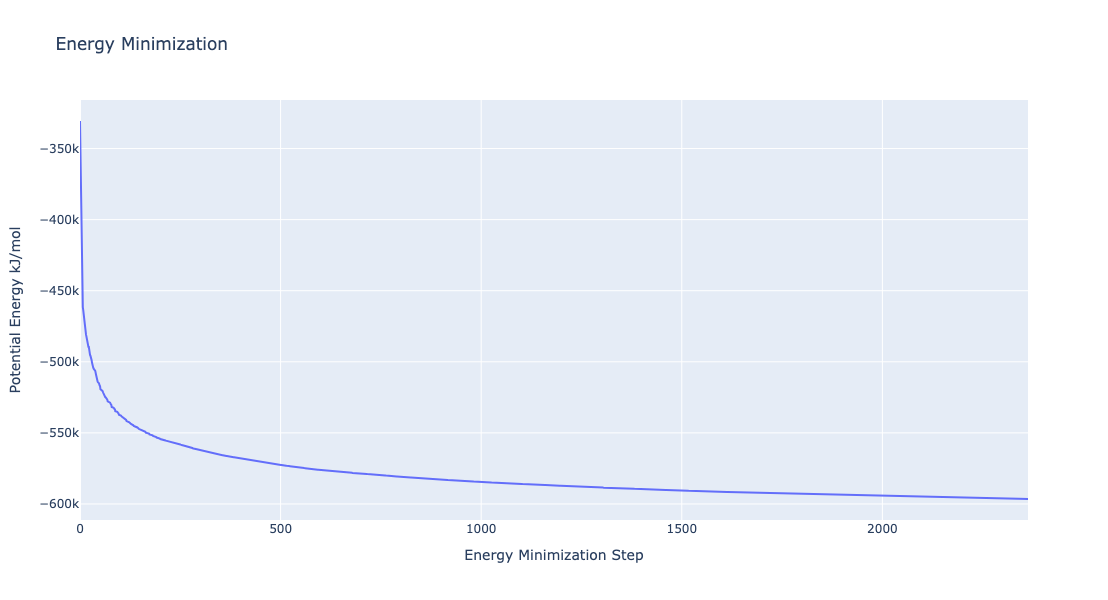

In [18]:
import plotly.graph_objs as go

# Read data from file and filter energy values higher than 1000 kJ/mol
with open(output_min_ene_xvg, 'r') as energy_file:
    x, y = zip(*[
        (float(line.split()[0]), float(line.split()[1]))
        for line in energy_file
        if not line.startswith(("#", "@"))
        if float(line.split()[1]) < 1000
    ])

# Create a scatter plot
fig = go.Figure(data=go.Scatter(x=x, y=y, mode='lines'))

# Update layout
fig.update_layout(title="Energy Minimization",
                  xaxis_title="Energy Minimization Step",
                  yaxis_title="Potential Energy kJ/mol",
                  height=600)

# Show the figure
fig.show()

<a id="nvt"></a>
***
## Equilibrate the system (NVT)
Equilibrate the **protein system** in **NVT ensemble** (constant Number of particles, Volume and Temperature). Protein **heavy atoms** will be restrained using position restraining forces: movement is permitted, but only after overcoming a substantial energy penalty. The utility of position restraints is that they allow us to equilibrate our solvent around our protein, without the added variable of structural changes in the protein.

- [Step 1](#eqNVTStep1): Creating portable binary run file for system equilibration
- [Step 2](#eqNVTStep2): Equilibrate the **protein system** with **NVT** ensemble.
- [Step 3](#eqNVTStep3): Checking **NVT Equilibration** results. Plotting **system temperature** by time during the **NVT equilibration** process. 
***
**Building Blocks** used:
- [Grompp](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.grompp) from **biobb_gromacs.gromacs.grompp** 
- [Mdrun](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.mdrun) from **biobb_gromacs.gromacs.mdrun** 
- [GMXEnergy](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_energy) from **biobb_analysis.gromacs.gmx_energy** 
***

<a id="eqNVTStep1"></a>
### Step 1: Creating portable binary run file for system equilibration (NVT)
The **nvt** type of the **molecular dynamics parameters (mdp) property** contains the main default parameters to run an **NVT equilibration** with **protein restraints** (see [GROMACS mdp options](http://manual.gromacs.org/documentation/2018/user-guide/mdp-options.html)):

-  Define                   = -DPOSRES
-  integrator               = md
-  dt                       = 0.002
-  nsteps                   = 5000
-  pcoupl                   = no
-  gen_vel                  = yes
-  gen_temp                 = 300
-  gen_seed                 = -1

In this particular example, the default parameters will be used: **md** integrator algorithm, a **step size** of **2fs**, **5,000 equilibration steps** with the protein **heavy atoms restrained**, and a temperature of **300K**.

*Please note that for the sake of time this tutorial is only running 10ps of NVT equilibration, whereas in the [original example](http://www.mdtutorials.com/gmx/lysozyme/06_equil.html) the simulated time was 100ps.*

In [19]:
# Grompp: Creating portable binary run file for NVT Equilibration
from biobb_gromacs.gromacs.grompp import grompp

# Create prop dict and inputs/outputs
output_gppnvt_tpr = pdbCode+'_gppnvt.tpr'
prop = {
    'mdp':{
        'nsteps': 5000,
        'dt': 0.002,
        'Define': '-DPOSRES',
        #'tc_grps': "DNA Water_and_ions" # NOTE: uncomment this line if working with DNA
    },
    'simulation_type': 'nvt'
}

# Create and launch bb
grompp(input_gro_path=output_min_gro, 
       input_top_zip_path=output_genion_top_zip, 
       output_tpr_path=output_gppnvt_tpr,  
       properties=prop)

2026-11-12 13:29:07,658 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.grompp Version: 5.3.2
2026-11-12 13:29:07,659 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_535c69eb-9f7d-42c0-b18f-4e437d951cf6
2026-11-12 13:29:07,660 [MainThread  ] [INFO ]  Copy to stage: 1AKI_min.gro --> sandbox_535c69eb-9f7d-42c0-b18f-4e437d951cf6
2026-11-12 13:29:07,664 [MainThread  ] [INFO ]  Extracting: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/1AKI_genion_top.zip
2026-11-12 13:29:07,664 [MainThread  ] [INFO ]  to:
2026-11-12 13:29:07,665 [MainThread  ] [INFO ]  ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_535c69eb-9f7d-42c0-b18f-4e437d951cf6/p2g.top', '/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_535c69eb-9f7d-42c0-b18f-4e437d951cf6/posre.itp']
2026-11

2026-11-12 13:29:08,031 [MainThread  ] [INFO ]                  :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup/bin.SSE2/gmx
Data prefix:  /Users/gbayarri/miniconda3/envs/biobb_wf_md_setup
Working dir:  /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_535c69eb-9f7d-42c0-b18f-4e437d951cf6
Command line:
  gmx -nobackup -nocopyright grompp -f grompp.mdp -c 1AKI_min.gro -r 1AKI_min.gro -p p2g.top -o 1AKI_gppnvt.tpr -po f296fd3f-80cb-4c3f-9f71-2803d4394fdcmdout.mdp -maxwarn 10

Ignoring obsolete mdp entry 'ns-type'
Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 4920.79
Number of degrees of freedom in T-Coupling group non-Protein is 63837.21

NOTE 1 [file grompp.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-mo

2026-11-12 13:29:08,034 [MainThread  ] [INFO ]  Removed: ['/Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_535c69eb-9f7d-42c0-b18f-4e437d951cf6']
2026-11-12 13:29:08,035 [MainThread  ] [INFO ]  


0

<a id="eqNVTStep2"></a>
### Step 2: Running NVT equilibration

In [ ]:
# Mdrun: Running Equilibration NVT
from biobb_gromacs.gromacs.mdrun import mdrun

# Create prop dict and inputs/outputs
output_nvt_trr = pdbCode+'_nvt.trr'
output_nvt_gro = pdbCode+'_nvt.gro'
output_nvt_edr = pdbCode+'_nvt.edr'
output_nvt_log = pdbCode+'_nvt.log'
output_nvt_cpt = pdbCode+'_nvt.cpt'

# Create and launch bb
mdrun(input_tpr_path=output_gppnvt_tpr, 
      output_trr_path=output_nvt_trr, 
      output_gro_path=output_nvt_gro, 
      output_edr_path=output_nvt_edr, 
      output_log_path=output_nvt_log, 
      output_cpt_path=output_nvt_cpt)

2026-11-12 13:29:09,153 [MainThread  ] [INFO ]  Module: biobb_gromacs.gromacs.mdrun Version: 5.3.2
2026-11-12 13:29:09,154 [MainThread  ] [INFO ]  Directory successfully created: /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_864f8f2a-6b50-4e61-8f6f-38fe507dbb35
2026-11-12 13:29:09,155 [MainThread  ] [INFO ]  Copy to stage: 1AKI_gppnvt.tpr --> sandbox_864f8f2a-6b50-4e61-8f6f-38fe507dbb35
2026-11-12 13:29:09,158 [MainThread  ] [INFO ]  Launching command (it may take a while): cd /Users/gbayarri/projects/BioBB/tutorials/biobb_wf_md_setup/biobb_wf_md_setup/notebooks/sandbox_864f8f2a-6b50-4e61-8f6f-38fe507dbb35 ; gmx -nobackup -nocopyright mdrun -s 1AKI_gppnvt.tpr -c 1AKI_nvt.gro -e 1AKI_nvt.edr -g 1AKI_nvt.log -o 1AKI_nvt.trr -cpo 1AKI_nvt.cpt


<a id="eqNVTStep3"></a>
### Step 3: Checking NVT Equilibration results
Checking **NVT Equilibration** results. Plotting **system temperature** by time during the NVT equilibration process. 

In [ ]:
# GMXEnergy: Getting system temperature by time during NVT Equilibration  
from biobb_analysis.gromacs.gmx_energy import gmx_energy

# Create prop dict and inputs/outputs
output_nvt_temp_xvg = pdbCode+'_nvt_temp.xvg'
prop = {
    'terms':  ["Temperature"]
}

# Create and launch bb
gmx_energy(input_energy_path=output_nvt_edr, 
          output_xvg_path=output_nvt_temp_xvg, 
          properties=prop)

In [ ]:
import plotly.graph_objs as go

# Read temperature data from file
with open(output_nvt_temp_xvg, 'r') as temperature_file:
    x, y = zip(*[
        (float(line.split()[0]), float(line.split()[1]))
        for line in temperature_file
        if not line.startswith(("#", "@"))
    ])

# Create a scatter plot
fig = go.Figure(data=go.Scatter(x=x, y=y, mode='lines+markers'))

# Update layout
fig.update_layout(title="Temperature during NVT Equilibration",
                  xaxis_title="Time (ps)",
                  yaxis_title="Temperature (K)",
                  height=600)

# Show the figure
fig.show()

<a id="npt"></a>
***
## Equilibrate the system (NPT)
Equilibrate the **protein system** in **NPT** ensemble (constant Number of particles, Pressure and Temperature).
- [Step 1](#eqNPTStep1): Creating portable binary run file for system equilibration
- [Step 2](#eqNPTStep2): Equilibrate the **protein system** with **NPT** ensemble.
- [Step 3](#eqNPTStep3): Checking **NPT Equilibration** results. Plotting **system pressure and density** by time during the **NPT equilibration** process.
***
**Building Blocks** used:
 - [Grompp](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.grompp) from **biobb_gromacs.gromacs.grompp** 
 - [Mdrun](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.mdrun) from **biobb_gromacs.gromacs.mdrun** 
 - [GMXEnergy](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_energy) from **biobb_analysis.gromacs.gmx_energy** 
***

<a id="eqNPTStep1"></a>
### Step 1: Creating portable binary run file for system equilibration (NPT)

The **npt** type of the **molecular dynamics parameters (mdp) property** contains the main default parameters to run an **NPT equilibration** with **protein restraints** (see [GROMACS mdp options](http://manual.gromacs.org/documentation/2018/user-guide/mdp-options.html)):

-  Define                   = -DPOSRES
-  integrator               = md
-  dt                       = 0.002
-  nsteps                   = 5000
-  pcoupl = Parrinello-Rahman
-  pcoupltype = isotropic
-  tau_p = 1.0
-  ref_p = 1.0
-  compressibility = 4.5e-5
-  refcoord_scaling = com
-  gen_vel = no

In this particular example, the default parameters will be used: **md** integrator algorithm, a **time step** of **2fs**, **5,000 equilibration steps** with the protein **heavy atoms restrained**, and a Parrinello-Rahman **pressure coupling** algorithm.

*Please note that for the sake of time this tutorial is only running 10ps of NPT equilibration, whereas in the [original example](http://www.mdtutorials.com/gmx/lysozyme/07_equil2.html) the simulated time was 100ps.*

In [ ]:
# Grompp: Creating portable binary run file for NPT System Equilibration
from biobb_gromacs.gromacs.grompp import grompp

# Create prop dict and inputs/outputs
output_gppnpt_tpr = pdbCode+'_gppnpt.tpr'
prop = {
    'mdp':{
        'nsteps':'5000',
        #'tc_grps': "DNA Water_and_ions" # NOTE: uncomment this line if working with DNA
    },
    'simulation_type': 'npt'
}

# Create and launch bb
grompp(input_gro_path=output_nvt_gro, 
       input_top_zip_path=output_genion_top_zip, 
       output_tpr_path=output_gppnpt_tpr, 
       input_cpt_path=output_nvt_cpt,  
       properties=prop)

<a id="eqNPTStep2"></a>
### Step 2: Running NPT equilibration

In [ ]:
# Mdrun: Running NPT System Equilibration
from biobb_gromacs.gromacs.mdrun import mdrun

# Create prop dict and inputs/outputs
output_npt_trr = pdbCode+'_npt.trr'
output_npt_gro = pdbCode+'_npt.gro'
output_npt_edr = pdbCode+'_npt.edr'
output_npt_log = pdbCode+'_npt.log'
output_npt_cpt = pdbCode+'_npt.cpt'

# Create and launch bb
mdrun(input_tpr_path=output_gppnpt_tpr, 
      output_trr_path=output_npt_trr, 
      output_gro_path=output_npt_gro, 
      output_edr_path=output_npt_edr, 
      output_log_path=output_npt_log, 
      output_cpt_path=output_npt_cpt)

<a id="eqNPTStep3"></a>
### Step 3: Checking NPT Equilibration results
Checking **NPT Equilibration** results. Plotting **system pressure and density** by time during the **NPT equilibration** process. 

In [ ]:
# GMXEnergy: Getting system pressure and density by time during NPT Equilibration  
from biobb_analysis.gromacs.gmx_energy import gmx_energy

# Create prop dict and inputs/outputs
output_npt_pd_xvg = pdbCode+'_npt_PD.xvg'
prop = {
    'terms':  ["Pressure","Density"]
}

# Create and launch bb
gmx_energy(input_energy_path=output_npt_edr, 
          output_xvg_path=output_npt_pd_xvg, 
          properties=prop)

In [ ]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots

# Read pressure and density data from file 
with open(output_npt_pd_xvg,'r') as pd_file:
    x, y, z = zip(*[
        (float(line.split()[0]), float(line.split()[1]), float(line.split()[2]))
        for line in pd_file
        if not line.startswith(("#", "@"))
    ])

trace1 = go.Scatter(
    x=x,y=y
)
trace2 = go.Scatter(
    x=x,y=z
)

fig = make_subplots(rows=1, cols=2, print_grid=False)
fig.append_trace(trace1, 1, 1)
fig.append_trace(trace2, 1, 2)

fig.update_layout(
    height=500,
    title='Pressure and Density during NPT Equilibration',
    showlegend=False,
    xaxis1_title='Time (ps)',
    yaxis1_title='Pressure (bar)',
    xaxis2_title='Time (ps)',
    yaxis2_title='Density (Kg*m^-3)'
)

# Show the figure
fig.show()

<a id="free"></a>
***
## Free Molecular Dynamics Simulation
Upon completion of the **two equilibration phases (NVT and NPT)**, the system is now well-equilibrated at the desired temperature and pressure. The **position restraints** can now be released. The last step of the **protein** MD setup is a short, **free MD simulation**, to ensure the robustness of the system. 
- [Step 1](#mdStep1): Creating portable binary run file to run a **free MD simulation**.
- [Step 2](#mdStep2): Run short MD simulation of the **protein system**.
- [Step 3](#mdStep3): Checking results for the final step of the setup process, the **free MD run**. Plotting **Root Mean Square deviation (RMSd)** and **Radius of Gyration (Rgyr)** by time during the **free MD run** step. 
***
**Building Blocks** used:
 - [Grompp](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.grompp) from **biobb_gromacs.gromacs.grompp** 
 - [Mdrun](https://biobb-md.readthedocs.io/en/latest/gromacs.html#module-gromacs.mdrun) from **biobb_gromacs.gromacs.mdrun** 
 - [GMXRms](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_rms) from **biobb_analysis.gromacs.gmx_rms** 
 - [GMXRgyr](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_rgyr) from **biobb_analysis.gromacs.gmx_rgyr** 
***

<a id="mdStep1"></a>
### Step 1: Creating portable binary run file to run a free MD simulation

The **free** type of the **molecular dynamics parameters (mdp) property** contains the main default parameters to run an **free MD simulation** (see [GROMACS mdp options](http://manual.gromacs.org/documentation/2018/user-guide/mdp-options.html)):

-  integrator               = md
-  dt                       = 0.002 (ps)
-  nsteps                   = 50000

In this particular example, the default parameters will be used: **md** integrator algorithm, a **time step** of **2fs**, and a total of **50,000 md steps** (100ps).

*Please note that for the sake of time this tutorial is only running 100ps of free MD, whereas in the [original example](http://www.mdtutorials.com/gmx/lysozyme/08_MD.html) the simulated time was 1ns (1000ps).*

In [ ]:
# Grompp: Creating portable binary run file for mdrun
from biobb_gromacs.gromacs.grompp import grompp

# Create prop dict and inputs/outputs
output_gppmd_tpr = pdbCode+'_gppmd.tpr'
prop = {
    'mdp':{
        'nsteps':'50000',
        #'tc_grps': "DNA Water_and_ions" # NOTE: uncomment this line if working with DNA
    },
    'simulation_type': 'free'
}

# Create and launch bb
grompp(input_gro_path=output_npt_gro, 
       input_top_zip_path=output_genion_top_zip, 
       output_tpr_path=output_gppmd_tpr, 
       input_cpt_path=output_npt_cpt, 
       properties=prop)

<a id="mdStep2"></a>
### Step 2: Running short free MD simulation

In [ ]:
# Mdrun: Running free dynamics
from biobb_gromacs.gromacs.mdrun import mdrun

# Create prop dict and inputs/outputs
output_md_trr = pdbCode+'_md.trr'
output_md_gro = pdbCode+'_md.gro'
output_md_edr = pdbCode+'_md.edr'
output_md_log = pdbCode+'_md.log'
output_md_cpt = pdbCode+'_md.cpt'

# Create and launch bb
mdrun(input_tpr_path=output_gppmd_tpr, 
      output_trr_path=output_md_trr, 
      output_gro_path=output_md_gro, 
      output_edr_path=output_md_edr, 
      output_log_path=output_md_log, 
      output_cpt_path=output_md_cpt)

<a id="mdStep3"></a>
### Step 3: Checking free MD simulation results
Checking results for the final step of the setup process, the **free MD run**. Plotting **Root Mean Square deviation (RMSd)** and **Radius of Gyration (Rgyr)** by time during the **free MD run** step. **RMSd** against the **experimental structure** (input structure of the pipeline) and against the **minimized and equilibrated structure** (output structure of the NPT equilibration step).

In [ ]:
# GMXRms: Computing Root Mean Square deviation to analyse structural stability 
#         RMSd against minimized and equilibrated snapshot (backbone atoms)   

from biobb_analysis.gromacs.gmx_rms import gmx_rms

# Create prop dict and inputs/outputs
output_rms_first = pdbCode+'_rms_first.xvg'
prop = {
    'selection':  'Backbone',
    #'selection': 'non-Water'
}

# Create and launch bb
gmx_rms(input_structure_path=output_gppmd_tpr,
         input_traj_path=output_md_trr,
         output_xvg_path=output_rms_first, 
          properties=prop)

In [ ]:
# GMXRms: Computing Root Mean Square deviation to analyse structural stability 
#         RMSd against experimental structure (backbone atoms)   

from biobb_analysis.gromacs.gmx_rms import gmx_rms

# Create prop dict and inputs/outputs
output_rms_exp = pdbCode+'_rms_exp.xvg'
prop = {
    'selection':  'Backbone',
    #'selection': 'non-Water'
}

# Create and launch bb
gmx_rms(input_structure_path=output_gppmin_tpr,
         input_traj_path=output_md_trr,
         output_xvg_path=output_rms_exp, 
          properties=prop)

In [ ]:
import plotly.graph_objs as go

# Read RMS vs first snapshot data from file 
with open(output_rms_first,'r') as rms_first_file:
    x, y = zip(*[
        (float(line.split()[0]), float(line.split()[1]))
        for line in rms_first_file
        if not line.startswith(("#", "@"))
    ])

# Read RMS vs experimental structure data from file 
with open(output_rms_exp,'r') as rms_exp_file:
    x2, y2 = zip(*[
        (float(line.split()[0]), float(line.split()[1]))
        for line in rms_exp_file
        if not line.startswith(("#", "@"))
    ])

fig = make_subplots()
fig.add_trace(go.Scatter(x=x, y=y, mode="lines+markers", name="RMSd vs first"))
fig.add_trace(go.Scatter(x=x, y=y2, mode="lines+markers", name="RMSd vs exp"))

# Set layout including height
fig.update_layout(
    title="RMSd during free MD Simulation",
    xaxis=dict(title="Time (ps)"),
    yaxis=dict(title="RMSd (nm)"),
    height=600
)

# Show the figure
fig.show()

In [ ]:
# GMXRgyr: Computing Radius of Gyration to measure the protein compactness during the free MD simulation 

from biobb_analysis.gromacs.gmx_rgyr import gmx_rgyr

# Create prop dict and inputs/outputs
output_rgyr = pdbCode+'_rgyr.xvg'
prop = {
    'selection':  'Backbone'
}

# Create and launch bb
gmx_rgyr(input_structure_path=output_gppmin_tpr,
         input_traj_path=output_md_trr,
         output_xvg_path=output_rgyr, 
          properties=prop)

In [ ]:
import plotly.graph_objs as go

# Read Rgyr data from file
with open(output_rgyr, 'r') as rgyr_file:
    x, y = zip(*[
        (float(line.split()[0]), float(line.split()[1]))
        for line in rgyr_file
        if not line.startswith(("#", "@"))
    ])

# Create a scatter plot
fig = go.Figure(data=go.Scatter(x=x, y=y, mode='lines+markers'))

# Update layout
fig.update_layout(title="Radius of Gyration",
                  xaxis_title="Time (ps)",
                  yaxis_title="Rgyr (nm)",
                  height=600)

# Show the figure
fig.show()

<a id="post"></a>
***
## Post-processing and Visualizing resulting 3D trajectory
Post-processing and Visualizing the **protein system** MD setup **resulting trajectory** using **Mol\***
- [Step 1](#ppStep1): *Imaging* the resulting trajectory, **stripping out water molecules and ions** and **correcting periodicity issues**.
- [Step 2](#ppStep2): Generating a *dry* structure, **removing water molecules and ions** from the final snapshot of the MD setup pipeline.
- [Step 3](#ppStep3): Visualizing the *imaged* trajectory using the *dry* structure as a **topology**. 
***
**Building Blocks** used:
 - [GMXImage](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_image) from **biobb_analysis.gromacs.gmx_image** 
 - [GMXTrjConvStr](https://biobb-analysis.readthedocs.io/en/latest/gromacs.html#module-gromacs.gmx_trjconv_str) from **biobb_analysis.gromacs.gmx_trjconv_str** 
***

<a id="ppStep1"></a>
### Step 1: *Imaging* the resulting trajectory.
Stripping out **water molecules and ions** and **correcting periodicity issues**  

In [ ]:
# GMXImage: "Imaging" the resulting trajectory
#           Removing water molecules and ions from the resulting structure
from biobb_analysis.gromacs.gmx_image import gmx_image

# Create prop dict and inputs/outputs
output_imaged_traj = pdbCode+'_imaged_traj.trr'
prop = {
    'center_selection':  'Protein',
    'output_selection': 'Protein',
    'pbc' : 'mol',
    'center' : True
}

# Create and launch bb
gmx_image(input_traj_path=output_md_trr,
         input_top_path=output_gppmd_tpr,
         output_traj_path=output_imaged_traj, 
          properties=prop)

<a id="ppStep2"></a>
### Step 2: Generating the output *dry* structure.
**Removing water molecules and ions** from the resulting structure

In [ ]:
# GMXTrjConvStr: Converting and/or manipulating a structure
#                Removing water molecules and ions from the resulting structure
#                The "dry" structure will be used as a topology to visualize 
#                the "imaged dry" trajectory generated in the previous step.
from biobb_analysis.gromacs.gmx_trjconv_str import gmx_trjconv_str

# Create prop dict and inputs/outputs
output_dry_gro = pdbCode+'_md_dry.gro'
prop = {
    'selection':  'Protein'
}

# Create and launch bb
gmx_trjconv_str(input_structure_path=output_md_gro,
         input_top_path=output_gppmd_tpr,
         output_str_path=output_dry_gro, 
          properties=prop)

<a id="ppStep3"></a>
### Step 3: Visualizing the generated dehydrated trajectory.
Using the **imaged trajectory** (output of the [Post-processing step 1](#ppStep1)) with the **dry structure** (output of the [Post-processing step 2](#ppStep2)) as a topology.
Use the **play** button at the top left of the viewer to animate the trajectory.

In [ ]:
# Show trajectory
builder = mvs.create_builder()
# Imaged trajectory coordinates
builder.download(url=output_imaged_traj).parse(format='trr').coordinates(ref='trajectory')
# Dry structure used as topology
structure = builder.download(url=output_dry_gro).parse(format='gro').model_structure(coordinates_ref='trajectory')
structure.component(selector='protein').representation(type='cartoon').color(custom={'molstar_color_theme_name': 'secondary-structure'})
data = {
    output_dry_gro: Path(output_dry_gro).read_bytes(),
    output_imaged_traj: Path(output_imaged_traj).read_bytes()
}
builder.molstar_notebook(data=data, width='100%', height=600)

<a id="output"></a>
## Output files

Important **Output files** generated:
 - **output_md_gro** (1aki_md.gro): **Final structure** (snapshot) of the MD setup protocol.
 - **output_md_trr** (1aki_md.trr): **Final trajectory** of the MD setup protocol.
 - **output_md_cpt** (1aki_md.cpt): **Final checkpoint file**, with information about the state of the simulation. It can be used to **restart** or **continue** a MD simulation.
 - **output_gppmd_tpr** (1aki_gppmd.tpr): **Final tpr file**, GROMACS portable binary run input file. This file contains the starting structure of the **MD setup free MD simulation step**, together with the molecular topology and all the simulation parameters. It can be used to **extend** the simulation.
 - **output_genion_top_zip** (1aki_genion_top.zip): **Final topology** of the MD system. It is a compressed zip file including a **topology file** (.top) and a set of auxiliary **include topology** files (.itp).

**Analysis** (MD setup check) output files generated:
 - **output_rms_first** (1aki_rms_first.xvg): **Root Mean Square deviation (RMSd)** against **minimized and equilibrated structure** of the final **free MD run step**.
 - **output_rms_exp** (1aki_rms_exp.xvg): **Root Mean Square deviation (RMSd)** against **experimental structure** of the final **free MD run step**.
 - **output_rgyr** (1aki_rgyr.xvg): **Radius of Gyration** of the final **free MD run step** of the **setup pipeline**.
 

***
<a id="questions"></a>

## Questions & Comments

Questions, issues, suggestions and comments are really welcome!

* GitHub issues:
    * [https://github.com/bioexcel/biobb](https://github.com/bioexcel/biobb)

* BioExcel forum:
    * [https://ask.bioexcel.eu/c/BioExcel-Building-Blocks-library](https://ask.bioexcel.eu/c/BioExcel-Building-Blocks-library)
